# Analisis Graf Berarah dan Tidak Berarah Menggunakan NetworkX

## 1. Pembuatan Graf
Membuat graf berarah (*Directed Graph*) dan graf tidak berarah (*Undirected Graph*) menggunakan 5 vertex dan 6 edge dengan library NetworkX.

## 2. Degree dan Distribusi Derajat
Menghitung jumlah hubungan setiap vertex serta distribusi frekuensi derajat pada masing-masing graf.

## 3. Rata-Rata Degree
Menghitung nilai rata-rata degree untuk mengetahui rata-rata jumlah hubungan setiap vertex.

## 4. Shortest Path
Menghitung lintasan terpendek antarvertex, rata-rata jarak terpendek, dan diameter graf.

## 5. Clustering Coefficient
Menghitung koefisien klasterisasi setiap vertex untuk mengetahui keterhubungan antarvertex tetangga.

## 6. Graph Density
Menghitung kepadatan graf berdasarkan perbandingan jumlah edge aktual dengan jumlah maksimum edge.

## 7. Adjacency Matrix
Menampilkan matriks ketetanggaan untuk merepresentasikan hubungan antarvertex dalam bentuk matriks.

## 8. Kesimpulan
Membandingkan hasil analisis graf berarah dan tidak berarah untuk mengetahui perbedaan karakteristik keduanya.

In [1]:
# ==========================================
# INSTALL SEMUA LIBRARY
# ==========================================

%pip install --upgrade pip

%pip install networkx matplotlib pandas numpy

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print("Semua library berhasil diimpor!")
print("NetworkX version:", nx.__version__)

Semua library berhasil diimpor!
NetworkX version: 3.7


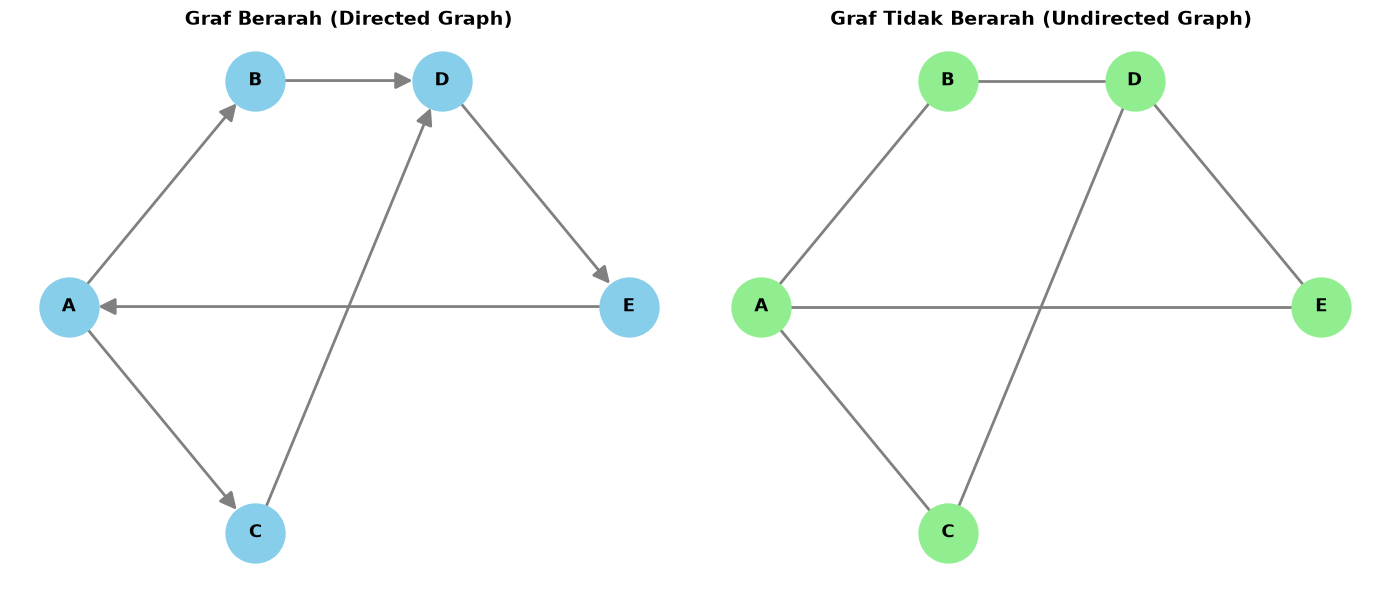


ANALISIS GRAF BERARAH

Jumlah Vertex : 5
Jumlah Edge   : 6

A. DEGREE SETIAP VERTEX
Vertex  In-Degree  Out-Degree  Total Degree
     A          1           2             3
     B          1           1             2
     C          1           1             2
     D          2           1             3
     E          1           1             2

B. DISTRIBUSI DEGREE

Distribusi In-Degree:
Degree
1    4
2    1

Distribusi Out-Degree:
Degree
1    4
2    1

Distribusi Total Degree:
Degree
2    3
3    2

C. RATA-RATA DEGREE
Average Degree : 2.4
Average In-Degree  : 1.2
Average Out-Degree : 1.2

D. JARAK TERPENDEK SETIAP PASANGAN VERTEX
Asal Tujuan    Lintasan Terpendek  Jarak
   A      B                A -> B      1
   A      C                A -> C      1
   A      D           A -> B -> D      2
   A      E      A -> B -> D -> E      3
   B      A      B -> D -> E -> A      3
   B      C B -> D -> E -> A -> C      4
   B      D                B -> D      1
   B      E           B -> D -

In [3]:

import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ==================================================
# 1. MEMBUAT DATA GRAF
# ==================================================

vertices = ["A", "B", "C", "D", "E"]

edges = [
    ("A", "B"),
    ("A", "C"),
    ("B", "D"),
    ("C", "D"),
    ("D", "E"),
    ("E", "A")
]

# Posisi vertex agar kedua graf mudah dibandingkan
pos = {
    "A": (0, 1),
    "B": (1.5, 2),
    "C": (1.5, 0),
    "D": (3, 2),
    "E": (4.5, 1)
}


# ==================================================
# 2. MEMBUAT GRAF BERARAH DAN TIDAK BERARAH
# ==================================================

G1 = nx.DiGraph()
G1.add_nodes_from(vertices)
G1.add_edges_from(edges)

G2 = nx.Graph()
G2.add_nodes_from(vertices)
G2.add_edges_from(edges)


# ==================================================
# 3. VISUALISASI GRAF
# ==================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Graf berarah
nx.draw(
    G1,
    pos,
    ax=axes[0],
    with_labels=True,
    node_color="skyblue",
    node_size=1800,
    font_size=13,
    font_weight="bold",
    edge_color="gray",
    width=2,
    arrows=True,
    arrowsize=25
)

axes[0].set_title(
    "Graf Berarah (Directed Graph)",
    fontsize=14,
    fontweight="bold"
)

# Graf tidak berarah
nx.draw(
    G2,
    pos,
    ax=axes[1],
    with_labels=True,
    node_color="lightgreen",
    node_size=1800,
    font_size=13,
    font_weight="bold",
    edge_color="gray",
    width=2
)

axes[1].set_title(
    "Graf Tidak Berarah (Undirected Graph)",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ==================================================
# 4. FUNGSI ANALISIS GRAF
# ==================================================

def analisis_graf(G, jenis):

    n = G.number_of_nodes()
    m = G.number_of_edges()

    print("\n" + "=" * 65)
    print("ANALISIS GRAF", jenis.upper())
    print("=" * 65)

    print("\nJumlah Vertex :", n)
    print("Jumlah Edge   :", m)

    # ------------------------------------------------
    # A. DEGREE SETIAP VERTEX
    # ------------------------------------------------

    print("\nA. DEGREE SETIAP VERTEX")

    if G.is_directed():

        degree_data = []

        for v in G.nodes():

            indeg = G.in_degree(v)
            outdeg = G.out_degree(v)
            total = G.degree(v)

            degree_data.append([
                v, indeg, outdeg, total
            ])

        df_degree = pd.DataFrame(
            degree_data,
            columns=[
                "Vertex",
                "In-Degree",
                "Out-Degree",
                "Total Degree"
            ]
        )

    else:

        degree_data = []

        for v in G.nodes():

            degree_data.append([
                v, G.degree(v)
            ])

        df_degree = pd.DataFrame(
            degree_data,
            columns=["Vertex", "Degree"]
        )

    print(df_degree.to_string(index=False))


    # ------------------------------------------------
    # B. DISTRIBUSI DEGREE
    # ------------------------------------------------

    print("\nB. DISTRIBUSI DEGREE")

    if G.is_directed():

        in_degree = dict(G.in_degree())
        out_degree = dict(G.out_degree())
        total_degree = dict(G.degree())

        print("\nDistribusi In-Degree:")
        print(
            pd.Series(list(in_degree.values()))
            .value_counts()
            .sort_index()
            .rename_axis("Degree")
            .to_string()
        )

        print("\nDistribusi Out-Degree:")
        print(
            pd.Series(list(out_degree.values()))
            .value_counts()
            .sort_index()
            .rename_axis("Degree")
            .to_string()
        )

        print("\nDistribusi Total Degree:")
        print(
            pd.Series(list(total_degree.values()))
            .value_counts()
            .sort_index()
            .rename_axis("Degree")
            .to_string()
        )

    else:

        degrees = dict(G.degree())

        distribution = (
            pd.Series(list(degrees.values()))
            .value_counts()
            .sort_index()
        )

        distribution.index.name = "Degree"
        distribution.name = "Frekuensi"

        print(distribution.to_string())


    # ------------------------------------------------
    # C. RATA-RATA DEGREE
    # ------------------------------------------------

    print("\nC. RATA-RATA DEGREE")

    avg_degree = sum(dict(G.degree()).values()) / n

    print("Average Degree :", round(avg_degree, 4))

    if G.is_directed():

        avg_in = sum(dict(G.in_degree()).values()) / n
        avg_out = sum(dict(G.out_degree()).values()) / n

        print("Average In-Degree  :", round(avg_in, 4))
        print("Average Out-Degree :", round(avg_out, 4))


    # ------------------------------------------------
    # D. AVERAGE SHORTEST PATH LENGTH
    # ------------------------------------------------

    print("\nD. JARAK TERPENDEK SETIAP PASANGAN VERTEX")

    distances = dict(nx.all_pairs_shortest_path_length(G))
    paths = dict(nx.all_pairs_shortest_path(G))

    shortest_data = []

    for asal in G.nodes():

        for tujuan in G.nodes():

            if asal == tujuan:
                continue

            if tujuan in distances[asal]:

                shortest_data.append([
                    asal,
                    tujuan,
                    " -> ".join(paths[asal][tujuan]),
                    distances[asal][tujuan]
                ])

    df_shortest = pd.DataFrame(
        shortest_data,
        columns=[
            "Asal",
            "Tujuan",
            "Lintasan Terpendek",
            "Jarak"
        ]
    )

    print(df_shortest.to_string(index=False))

    # Menghitung rata-rata shortest path
    if G.is_directed():
        connected = nx.is_strongly_connected(G)
    else:
        connected = nx.is_connected(G)

    if connected:

        avg_shortest = nx.average_shortest_path_length(G)
        diameter = nx.diameter(G)

        print("\nAverage Shortest Path Length :",
              round(avg_shortest, 4))

        print("Diameter Graf                :", diameter)

    else:

        avg_shortest = None

        print("Graf tidak terhubung secara keseluruhan.")
        print("Average Shortest Path dan diameter global tidak tersedia.")


    # ------------------------------------------------
    # E. CLUSTERING COEFFICIENT
    # ------------------------------------------------

    print("\nE. KOEFISIEN KLASTERISASI")

    clustering = nx.clustering(G)

    df_clustering = pd.DataFrame(
        list(clustering.items()),
        columns=[
            "Vertex",
            "Clustering Coefficient"
        ]
    )

    print(df_clustering.to_string(index=False))

    avg_clustering = nx.average_clustering(G)

    print("\nAverage Clustering Coefficient :",
          round(avg_clustering, 4))


    # ------------------------------------------------
    # F. GRAPH DENSITY
    # ------------------------------------------------

    print("\nF. KEPADATAN GRAF (GRAPH DENSITY)")

    density = nx.density(G)

    if G.is_directed():
        max_edges = n * (n - 1)
    else:
        max_edges = n * (n - 1) / 2

    print("Edge Aktual    :", m)
    print("Edge Maksimal  :", int(max_edges))
    print("Graph Density  :", round(density, 4))
    print("Density (%)    :", round(density * 100, 2), "%")


    # ------------------------------------------------
    # G. ADJACENCY MATRIX
    # ------------------------------------------------

    print("\nG. MATRIKS ADJACENCY")

    matrix = nx.to_numpy_array(
        G,
        nodelist=vertices,
        dtype=int
    )

    df_matrix = pd.DataFrame(
        matrix,
        index=vertices,
        columns=vertices
    )

    print(df_matrix.to_string())


    # ------------------------------------------------
    # H. VERIFIKASI
    # ------------------------------------------------

    print("\nH. VERIFIKASI")

    print("Total Degree :", sum(dict(G.degree()).values()))

    if G.is_directed():

        print("Total In-Degree  :",
              sum(dict(G.in_degree()).values()))

        print("Total Out-Degree :",
              sum(dict(G.out_degree()).values()))

    else:

        print("2 x Jumlah Edge :",
              2 * G.number_of_edges())

    return {
        "average_degree": avg_degree,
        "average_shortest": avg_shortest,
        "average_clustering": avg_clustering,
        "density": density,
        "diameter": diameter if connected else None
    }


# ==================================================
# 5. ANALISIS GRAF BERARAH
# ==================================================

hasil_berarah = analisis_graf(
    G1,
    "Berarah"
)


# ==================================================
# 6. ANALISIS GRAF TIDAK BERARAH
# ==================================================

hasil_tidak_berarah = analisis_graf(
    G2,
    "Tidak Berarah"
)


# ==================================================
# 7. PERBANDINGAN HASIL KEDUA GRAF
# ==================================================

print("\n" + "=" * 65)
print("PERBANDINGAN HASIL ANALISIS GRAF")
print("=" * 65)

comparison = pd.DataFrame({
    "Parameter": [
        "Jumlah Vertex",
        "Jumlah Edge",
        "Average Degree",
        "Average Shortest Path",
        "Average Clustering Coefficient",
        "Graph Density",
        "Diameter"
    ],

    "Graf Berarah": [
        G1.number_of_nodes(),
        G1.number_of_edges(),
        hasil_berarah["average_degree"],
        hasil_berarah["average_shortest"],
        hasil_berarah["average_clustering"],
        hasil_berarah["density"],
        hasil_berarah["diameter"]
    ],

    "Graf Tidak Berarah": [
        G2.number_of_nodes(),
        G2.number_of_edges(),
        hasil_tidak_berarah["average_degree"],
        hasil_tidak_berarah["average_shortest"],
        hasil_tidak_berarah["average_clustering"],
        hasil_tidak_berarah["density"],
        hasil_tidak_berarah["diameter"]
    ]
})

print(comparison.to_string(index=False))
